In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

processed_path = Path("../data/processed")
figures_path = Path("../reports/figures")

risk_data = pd.read_csv(
    processed_path / "finrisk_decision_intelligence.csv"
)

print("Dataset shape:", risk_data.shape)

display(risk_data.head())

Dataset shape: (10000, 26)


,customer_id,credit_risk_probability,credit_risk_score,temporal_risk_probability,temporal_risk_score,avg_fraud_probability,max_fraud_probability,avg_anomaly_score,max_anomaly_score,avg_hybrid_fraud_score,...,risk_category,calibrated_credit_probability,credit_uncertainty_score,credit_confidence_score,credit_uncertainty_category,human_review_required,decision,decision_reason,recommended_action,decision_confidence
0,100001,0.393545,39.354540,0.351935,35.193510,0.262764,0.783083,0.185125,0.816251,0.239472,...,Moderate,0.367032,0.734065,0.265935,High Uncertainty,True,Human Review,Elevated fraud risk; High model uncertainty,Escalate to human analyst for manual assessment,0.265935
1,100002,0.665469,66.546906,0.315314,31.531355,0.313527,0.803767,0.221139,0.709282,0.285810,...,Moderate,0.549241,0.901517,0.098483,High Uncertainty,True,Human Review,Elevated credit risk; High model uncertainty,Escalate to human analyst for manual assessment,0.098483
2,100003,0.515152,51.515220,0.410704,41.070427,0.476873,0.783061,0.261322,0.502814,0.412207,...,Moderate,0.451192,0.902384,0.097616,High Uncertainty,True,Human Review,Elevated credit risk; Elevated fraud risk; Hig...,Escalate to human analyst for manual assessment,0.097616
3,100004,0.411317,41.131725,0.357690,35.768967,0.266366,0.797005,0.227899,0.488348,0.254826,...,Moderate,0.364358,0.728716,0.271284,High Uncertainty,True,Human Review,High model uncertainty,Escalate to human analyst for manual assessment,0.271284
4,100005,0.573910,57.391030,0.325702,32.570225,0.295973,0.812917,0.247687,0.494577,0.281487,...,Moderate,0.434674,0.869349,0.130651,High Uncertainty,True,Human Review,Elevated credit risk; Elevated fraud risk; Hig...,Escalate to human analyst for manual assessment,0.130651


In [2]:
required_columns = [
    "customer_id",
    "credit_risk_score",
    "temporal_risk_score",
    "fraud_risk_score",
    "graph_risk_score",
    "financial_health_risk_score",
    "finrisk_score",
    "risk_category",
    "credit_uncertainty_score",
    "credit_confidence_score",
    "human_review_required",
    "decision"
]

missing_columns = [
    col for col in required_columns
    if col not in risk_data.columns
]

if missing_columns:
    print("Missing columns:")
    print(missing_columns)
else:
    print("✓ All required evaluation columns are present")

✓ All required evaluation columns are present


In [3]:
evaluation_metrics = pd.DataFrame({
    "Metric": [
        "Number of Customers",
        "Average FinRisk Score",
        "Median FinRisk Score",
        "Minimum FinRisk Score",
        "Maximum FinRisk Score",
        "Average Credit Risk",
        "Average Temporal Risk",
        "Average Fraud Risk",
        "Average Graph Risk",
        "Average Financial Health Risk"
    ],
    "Value": [
        len(risk_data),
        risk_data["finrisk_score"].mean(),
        risk_data["finrisk_score"].median(),
        risk_data["finrisk_score"].min(),
        risk_data["finrisk_score"].max(),
        risk_data["credit_risk_score"].mean(),
        risk_data["temporal_risk_score"].mean(),
        risk_data["fraud_risk_score"].mean(),
        risk_data["graph_risk_score"].mean(),
        risk_data["financial_health_risk_score"].mean()
    ]
})

display(evaluation_metrics)

,Metric,Value
0,Number of Customers,10000.000000
1,Average FinRisk Score,36.727223
2,Median FinRisk Score,35.321626
3,Minimum FinRisk Score,18.663046
4,Maximum FinRisk Score,65.841460
5,Average Credit Risk,32.372796
6,Average Temporal Risk,32.206396
7,Average Fraud Risk,51.962337
8,Average Graph Risk,25.663163
9,Average Financial Health Risk,37.340461


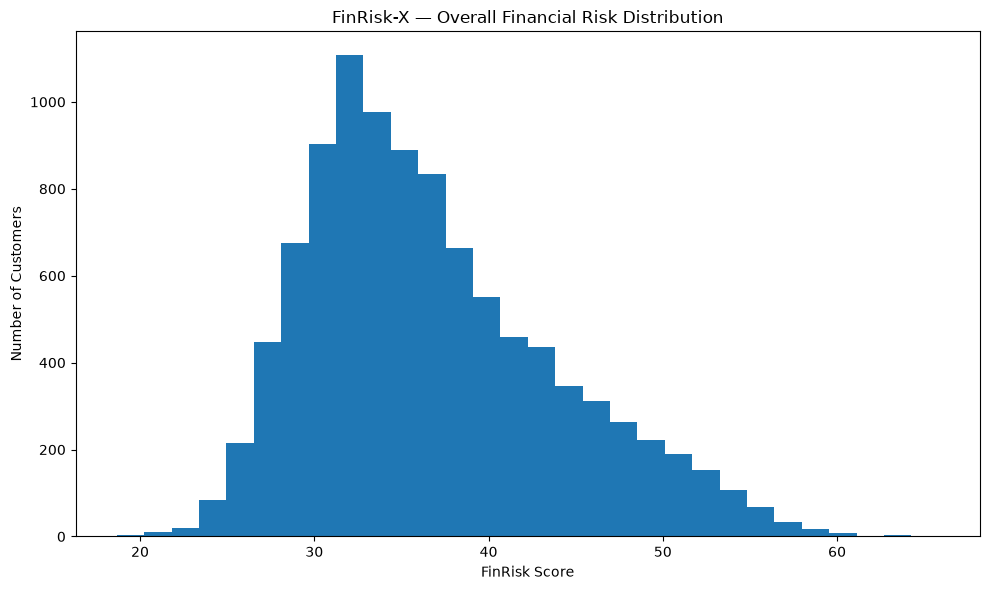

In [4]:
plt.figure(figsize=(10, 6))

plt.hist(
    risk_data["finrisk_score"],
    bins=30
)

plt.xlabel("FinRisk Score")
plt.ylabel("Number of Customers")
plt.title("FinRisk-X — Overall Financial Risk Distribution")

plt.tight_layout()

plt.savefig(
    figures_path / "final_finrisk_score_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [5]:
component_columns = {
    "Credit Risk": "credit_risk_score",
    "Temporal Risk": "temporal_risk_score",
    "Fraud Risk": "fraud_risk_score",
    "Graph Risk": "graph_risk_score",
    "Financial Health Risk": "financial_health_risk_score"
}

component_summary = pd.DataFrame({
    "Risk Component": component_columns.keys(),
    "Average Score": [
        risk_data[col].mean()
        for col in component_columns.values()
    ],
    "Median Score": [
        risk_data[col].median()
        for col in component_columns.values()
    ],
    "Std Dev": [
        risk_data[col].std()
        for col in component_columns.values()
    ]
})

display(component_summary)

,Risk Component,Average Score,Median Score,Std Dev
0,Credit Risk,32.372796,27.609772,20.203427
1,Temporal Risk,32.206396,31.864887,6.514323
2,Fraud Risk,51.962337,51.759976,5.550479
3,Graph Risk,25.663163,26.394009,10.913135
4,Financial Health Risk,37.340461,37.224039,6.445791


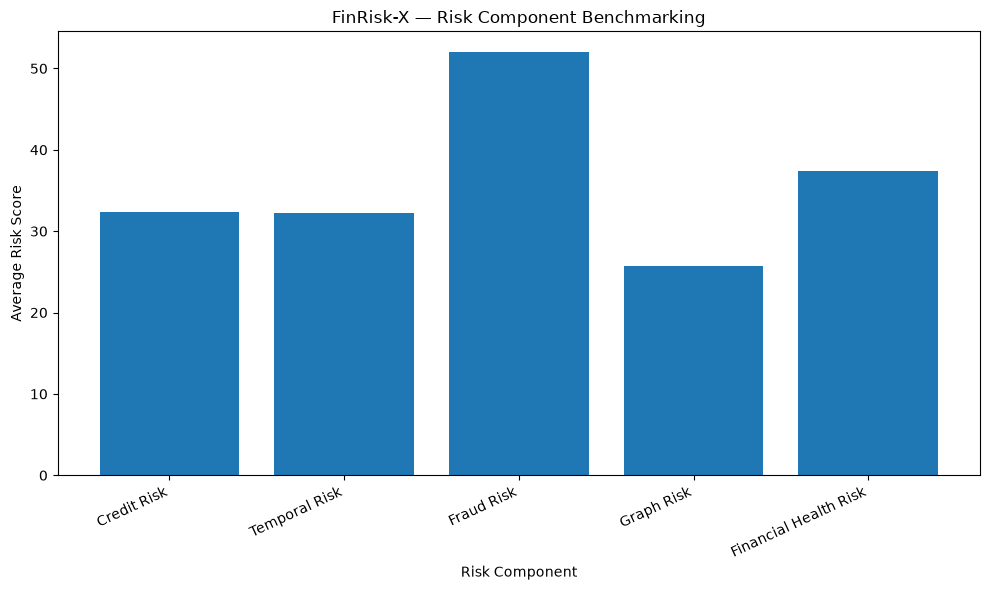

In [6]:
plt.figure(figsize=(10, 6))

plt.bar(
    component_summary["Risk Component"],
    component_summary["Average Score"]
)

plt.xlabel("Risk Component")
plt.ylabel("Average Risk Score")
plt.title("FinRisk-X — Risk Component Benchmarking")

plt.xticks(rotation=25, ha="right")

plt.tight_layout()

plt.savefig(
    figures_path / "risk_component_benchmarking.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [7]:
component_data = risk_data[
    list(component_columns.values())
].copy()

correlation_matrix = component_data.corr()

display(correlation_matrix)

,credit_risk_score,temporal_risk_score,fraud_risk_score,graph_risk_score,financial_health_risk_score
credit_risk_score,1.000000,0.319702,0.013977,-0.023778,0.256315
temporal_risk_score,0.319702,1.000000,-0.009856,-0.107836,0.059003
fraud_risk_score,0.013977,-0.009856,1.000000,0.262114,0.071315
graph_risk_score,-0.023778,-0.107836,0.262114,1.000000,0.061659
financial_health_risk_score,0.256315,0.059003,0.071315,0.061659,1.000000


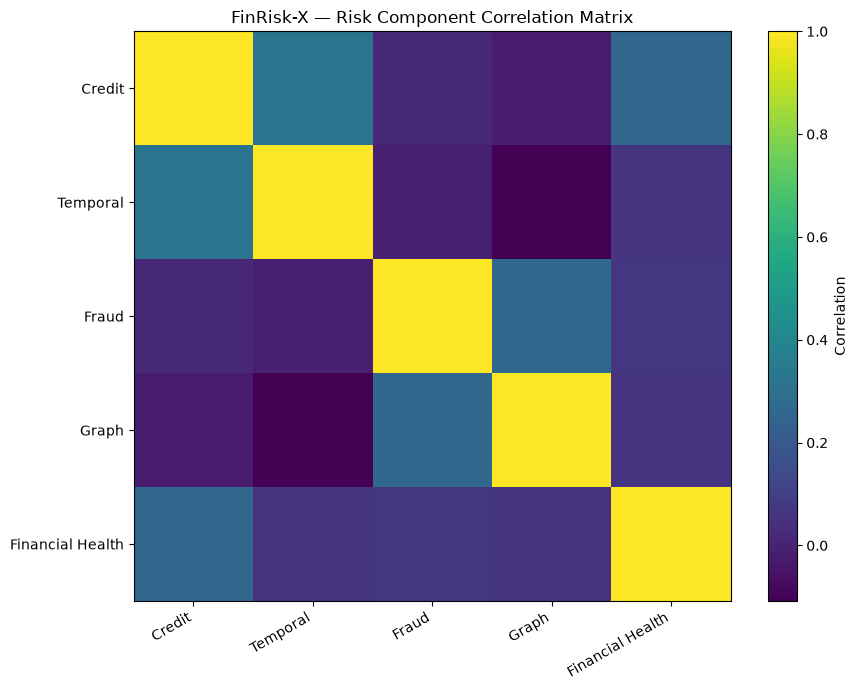

In [8]:
plt.figure(figsize=(9, 7))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Correlation"
)

plt.xticks(
    range(len(correlation_matrix.columns)),
    [
        "Credit",
        "Temporal",
        "Fraud",
        "Graph",
        "Financial Health"
    ],
    rotation=30,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    [
        "Credit",
        "Temporal",
        "Fraud",
        "Graph",
        "Financial Health"
    ]
)

plt.title(
    "FinRisk-X — Risk Component Correlation Matrix"
)

plt.tight_layout()

plt.savefig(
    figures_path / "risk_component_correlation.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [9]:
uncertainty_summary = pd.DataFrame({
    "Metric": [
        "Average Uncertainty",
        "Median Uncertainty",
        "Maximum Uncertainty",
        "Average Confidence",
        "Low Uncertainty %",
        "Moderate Uncertainty %",
        "High Uncertainty %",
        "Human Review %"
    ],
    "Value": [
        risk_data["credit_uncertainty_score"].mean(),
        risk_data["credit_uncertainty_score"].median(),
        risk_data["credit_uncertainty_score"].max(),
        risk_data["credit_confidence_score"].mean(),
        (
            risk_data["credit_uncertainty_category"]
            .eq("Low Uncertainty").mean() * 100
        ),
        (
            risk_data["credit_uncertainty_category"]
            .eq("Moderate Uncertainty").mean() * 100
        ),
        (
            risk_data["credit_uncertainty_category"]
            .eq("High Uncertainty").mean() * 100
        ),
        (
            risk_data["human_review_required"].astype(bool).mean() * 100
        )
    ]
})

display(uncertainty_summary)

,Metric,Value
0,Average Uncertainty,0.598089
1,Median Uncertainty,0.564432
2,Maximum Uncertainty,0.999861
3,Average Confidence,0.401911
4,Low Uncertainty %,0.000000
5,Moderate Uncertainty %,18.070000
6,High Uncertainty %,81.930000
7,Human Review %,81.930000


In [10]:
decision_summary = (
    risk_data
    .groupby("decision")
    .agg(
        customer_count=("customer_id", "count"),
        average_risk=("finrisk_score", "mean"),
        average_confidence=("decision_confidence", "mean")
    )
    .reset_index()
)

decision_summary["percentage"] = (
    decision_summary["customer_count"]
    / len(risk_data)
    * 100
)

display(decision_summary)

,decision,customer_count,average_risk,average_confidence,percentage
0,Approve,1807,29.395863,0.643049,18.07
1,Human Review,8193,38.344185,0.348727,81.93


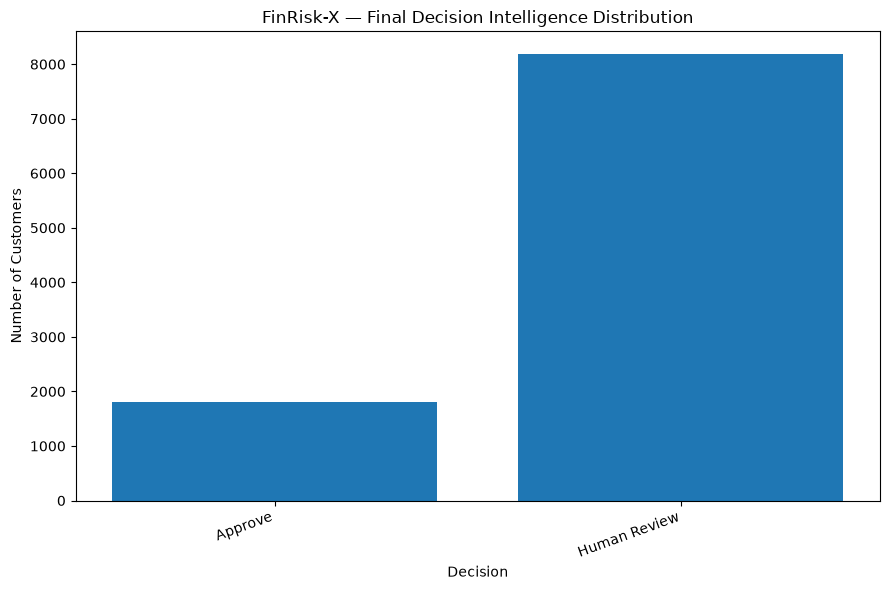

In [11]:
plt.figure(figsize=(9, 6))

plt.bar(
    decision_summary["decision"],
    decision_summary["customer_count"]
)

plt.xlabel("Decision")
plt.ylabel("Number of Customers")
plt.title(
    "FinRisk-X — Final Decision Intelligence Distribution"
)

plt.xticks(rotation=20, ha="right")

plt.tight_layout()

plt.savefig(
    figures_path / "final_decision_distribution.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [12]:
risk_data["high_risk_flag"] = (
    risk_data["finrisk_score"] >= 50
)

risk_data["critical_risk_flag"] = (
    risk_data["finrisk_score"] > 75
)

high_risk_summary = pd.DataFrame({
    "Category": [
        "Low/Moderate Risk",
        "High Risk",
        "Critical Risk"
    ],
    "Customers": [
        (~risk_data["high_risk_flag"]).sum(),
        risk_data["high_risk_flag"].sum(),
        risk_data["critical_risk_flag"].sum()
    ]
})

high_risk_summary["Percentage"] = (
    high_risk_summary["Customers"]
    / len(risk_data)
    * 100
)

display(high_risk_summary)

,Category,Customers,Percentage
0,Low/Moderate Risk,9406,94.06
1,High Risk,594,5.94
2,Critical Risk,0,0.00


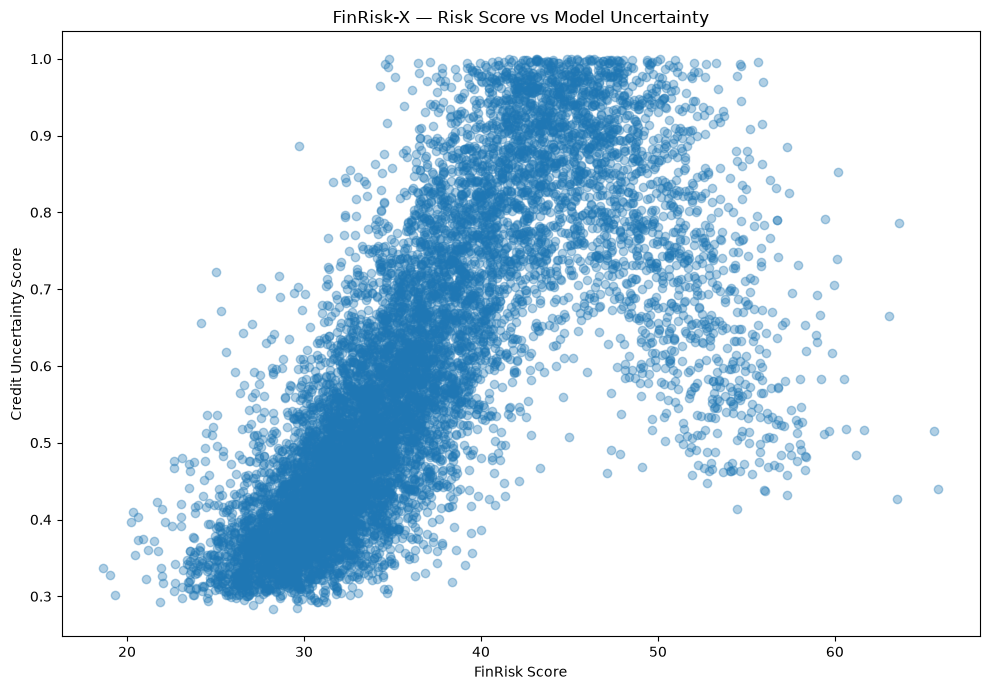

In [13]:
plt.figure(figsize=(10, 7))

plt.scatter(
    risk_data["finrisk_score"],
    risk_data["credit_uncertainty_score"],
    alpha=0.35
)

plt.xlabel("FinRisk Score")
plt.ylabel("Credit Uncertainty Score")

plt.title(
    "FinRisk-X — Risk Score vs Model Uncertainty"
)

plt.tight_layout()

plt.savefig(
    figures_path / "risk_vs_uncertainty.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [14]:
review_analysis = (
    risk_data
    .groupby("human_review_required")
    .agg(
        customer_count=("customer_id", "count"),
        average_risk=("finrisk_score", "mean"),
        average_uncertainty=("credit_uncertainty_score", "mean"),
        average_confidence=("credit_confidence_score", "mean")
    )
    .reset_index()
)

display(review_analysis)

,human_review_required,customer_count,average_risk,average_uncertainty,average_confidence
0,False,1807,29.395863,0.356951,0.643049
1,True,8193,38.344185,0.651273,0.348727


In [15]:
final_benchmark = pd.DataFrame({
    "Evaluation Dimension": [
        "Risk Coverage",
        "Temporal Modeling",
        "Fraud Detection",
        "Graph Risk",
        "Financial Health",
        "Risk Fusion",
        "Probability Calibration",
        "Uncertainty Estimation",
        "Explainability",
        "Fairness Analysis",
        "Decision Intelligence"
    ],
    "Implemented": [
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes"
    ]
})

display(final_benchmark)

,Evaluation Dimension,Implemented
0,Risk Coverage,Yes
1,Temporal Modeling,Yes
2,Fraud Detection,Yes
3,Graph Risk,Yes
4,Financial Health,Yes
5,Risk Fusion,Yes
6,Probability Calibration,Yes
7,Uncertainty Estimation,Yes
8,Explainability,Yes
9,Fairness Analysis,Yes


In [16]:
evaluation_metrics.to_csv(
    processed_path / "final_evaluation_metrics.csv",
    index=False
)

component_summary.to_csv(
    processed_path / "risk_component_benchmark.csv",
    index=False
)

uncertainty_summary.to_csv(
    processed_path / "uncertainty_evaluation.csv",
    index=False
)

decision_summary.to_csv(
    processed_path / "decision_evaluation.csv",
    index=False
)

high_risk_summary.to_csv(
    processed_path / "high_risk_evaluation.csv",
    index=False
)

review_analysis.to_csv(
    processed_path / "human_review_evaluation.csv",
    index=False
)

print("✓ Evaluation results saved")

✓ Evaluation results saved


In [17]:
expected_files = [
    processed_path / "final_evaluation_metrics.csv",
    processed_path / "risk_component_benchmark.csv",
    processed_path / "uncertainty_evaluation.csv",
    processed_path / "decision_evaluation.csv",
    processed_path / "high_risk_evaluation.csv",
    processed_path / "human_review_evaluation.csv",

    figures_path / "final_finrisk_score_distribution.svg",
    figures_path / "risk_component_benchmarking.svg",
    figures_path / "risk_component_correlation.svg",
    figures_path / "final_decision_distribution.svg",
    figures_path / "risk_vs_uncertainty.svg"
]

print("PHASE 15 VALIDATION\n")

for file in expected_files:
    print(
        f"{file.name:<55}",
        "✓" if file.exists() else "✗"
    )

PHASE 15 VALIDATION

final_evaluation_metrics.csv                            ✓
risk_component_benchmark.csv                            ✓
uncertainty_evaluation.csv                              ✓
decision_evaluation.csv                                 ✓
high_risk_evaluation.csv                                ✓
human_review_evaluation.csv                             ✓
final_finrisk_score_distribution.svg                    ✓
risk_component_benchmarking.svg                         ✓
risk_component_correlation.svg                          ✓
final_decision_distribution.svg                         ✓
risk_vs_uncertainty.svg                                 ✓
